##### Simple Linear Regression : 
Models the linear relationship between a single independent predictor variable ($x$) and a continuous dependent target variable ($y$).
$$\hat{y} = \beta_0 + \beta_1 x$$
### Objectives
1. Understand the mechanics of **Ordinary Least Squares (OLS)** optimization.
   OLS is an optimization method used to find the best-fitting line in Linear Regression by minimizing the sum of the squared differences between actual values and predicted values.
2. Derivation of closed-form parameters: Intercept ($\beta_0$) and Slope ($\beta_1$).
3. Compute and visualize residual errors ($e_i = y_i - \hat{y}_i$).
4. Implement `LinearRegression` using `scikit-learn` and interpret coefficients.



In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

In [11]:
np.random.seed(42)
n_samples = 50
years_experience = np.random.uniform(1,12,n_samples)
true_slope = 9500
true_intercept = 30000
noise = np.random.normal(0, 6000, size=n_samples)
salary = true_intercept + years_experience * true_slope + noise
df_simple = pd.DataFrame({
    'years_experience': years_experience,
    'salary': salary
})
print(df_simple.head())

   years_experience         salary
0          5.119941   83070.241900
1         11.457857  139877.854707
2          9.051933  115299.477225
3          7.585243  100253.189425
4          2.716205   46932.815984


#### 1. Closed-Form Analytical Solution (OLS Mathematics)
 Under Ordinary Least Squares, $\beta_1$ and $\beta_0$ are derived by minimizing the Sum of Squared Residuals ($\text{SSR}$):

$$\beta_1 = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sum_{i=1}^{n} (x_i - \bar{x})^2} = \frac{\text{Cov}(x, y)}{\text{Var}(x)}$$

$$\beta_0 = \bar{y} - \beta_1 \bar{x}$$

In [12]:
x = df_simple["years_experience"].values
y = df_simple["salary"].values
x_mean = np.mean(x)
y_mean = np.mean(y)

beta_1_manual = np.sum((x - x_mean) * (y - y_mean)) / np.sum((x - x_mean) ** 2)
beta_0_manual = y_mean - beta_1_manual * x_mean

print(f"Manual OLS Slope (Beta 1):     ₹{beta_1_manual:.2f} per year") # true_slope
print(f"Manual OLS Intercept (Beta 0): ₹{beta_0_manual:.2f}") # true_intercept

Manual OLS Slope (Beta 1):     ₹9378.13 per year
Manual OLS Intercept (Beta 0): ₹30702.01


In [15]:
X = df_simple[["years_experience"]]
# print("Value of X: ", X.values)
Y = df_simple["salary"]
model = LinearRegression()
model.fit(X,y)
print(f"Scikit-Learn Slope (Beta 1):     ₹{model.coef_[0]:.2f} per year") # asking what is coef
# model.coef_ gives the slope (coefficient) learned by the Linear Regression model after training.
print(f"Scikit-Learn Intercept (Beta 0): ₹{model.intercept_:.2f}") # true_intercept
# model.intercept_ gives the intercept learned by the Linear Regression model during training.

Scikit-Learn Slope (Beta 1):     ₹9378.13 per year
Scikit-Learn Intercept (Beta 0): ₹30702.01


In [18]:
print(df_simple.head())
print("="*60)
new_experience  = pd.DataFrame({"years_experience": [5.2,11.4,9.0,7.5,2.7,25]}) 
predicted_salary = model.predict(new_experience)
# print(predicted_salary)
for exp, sal in zip(new_experience["years_experience"],predicted_salary):
    print(f"Predicted salary for {exp} years of experience: ₹{sal:.2f}")

   years_experience         salary
0          5.119941   83070.241900
1         11.457857  139877.854707
2          9.051933  115299.477225
3          7.585243  100253.189425
4          2.716205   46932.815984
Predicted salary for 5.2 years of experience: ₹79468.27
Predicted salary for 11.4 years of experience: ₹137612.66
Predicted salary for 9.0 years of experience: ₹115105.15
Predicted salary for 7.5 years of experience: ₹101037.96
Predicted salary for 2.7 years of experience: ₹56022.95
Predicted salary for 25.0 years of experience: ₹265155.18


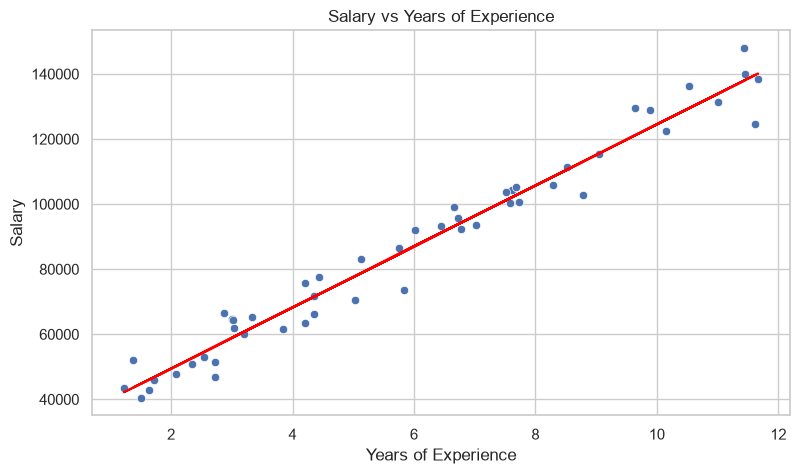

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

sns.scatterplot(x = "years_experience", y="salary", data=df_simple)
plt.plot(df_simple["years_experience"], model.predict(df_simple[["years_experience"]]), color="red")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Salary vs Years of Experience")
plt.show()